# PCA explained-variance analysis for EEG-CASCADE

This notebook quantifies how much variance is retained by the fixed 30-component PCA representation used in the EEG-CASCADE analyses.

**Important:** PCA is evaluated using **training interictal EEG only**, exactly matching the main v4 analysis pipeline. The notebook imports the existing v4 scripts and reuses their dataset parsing, scan construction, filtering, common montage handling, engineered feature extraction, and patient-specific train/validation/test split. No preictal or ictal test data are used to fit the scaler or PCA.

Outputs:
- patient-level cumulative explained-variance curves;
- variance retained by the first 30 principal components;
- number of components required to reach 80%, 90%, 95%, and 99% explained variance;
- manuscript-quality PNG/PDF figures;
- CSV summary tables.

Run CHB-MIT first. TUSZ is optional and can be enabled in the configuration cell.


In [1]:
from pathlib import Path
from types import SimpleNamespace
import importlib.util

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ================================================================
# USER CONFIGURATION
# ================================================================

CHBMIT_DATA_ROOT = Path("/data/halders2/EEG_anomaly/Data")
TUSZ_DATA_ROOT = Path("/data/halders2/EEG_anomaly/TUH_EEG_data/v2.0.6")

# Point these to the latest v4 analysis scripts on Biowulf.
CHBMIT_V4_SCRIPT = Path("chbmit_dynml_ictal_detection_BD_v4_fixed.py")
TUSZ_V4_SCRIPT = Path("tusz_dynml_ictal_detection_BD_v4.py")

RUN_CHBMIT = True
RUN_TUSZ = True     # Set True if you also want the TUSZ PCA analysis.

OUT_DIR = Path("pca_explained_variance_analysis")
FIG_DIR = OUT_DIR / "figures"
TABLE_DIR = OUT_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

TARGET_PCA = 30
DATA_SEED = 17

CHBMIT_PATIENTS = [f"chb{i:02d}" for i in range(1, 25)]

TUSZ_PATIENTS = ['aaaaapks', 'aaaaaqtx', 'aaaaahie', 'aaaaajqo', 'aaaaajru', 'aaaaaovk', 'aaaaardk', 'aaaaabhz', 'aaaaampk', 'aaaaaprj', 'aaaaafcf', 'aaaaaqkb', 'aaaaarsm', 'aaaaaedy', 'aaaaardf', 'aaaaaelb', 'aaaaacqc', 'aaaaatez', 'aaaaanme', 'aaaaaghb', 'aaaaaksg', 'aaaaamqq', 'aaaaaskf', 'aaaaatjh', 'aaaaates', 'aaaaarpv', 'aaaaaizz', 'aaaaafjw', 'aaaaaooo', 'aaaaadkj', 'aaaaarnq', 'aaaaaroo', 'aaaaaasy', 'aaaaajsl', 'aaaaakkm', 'aaaaakoe', 'aaaaamod', 'aaaaaasf', 'aaaaamoa', 'aaaaaqvx', 'aaaaamhj', 'aaaaarsp', 'aaaaaswc', 'aaaaalfs', 'aaaaamta', 'aaaaaqbb', 'aaaaaqtw', 'aaaaaqld', 'aaaaammu', 'aaaaasgd', 'aaaaapas', 'aaaaamnk', 'aaaaajfq', 'aaaaatds', 'aaaaaksh', 'aaaaaccj', 'aaaaaqrs', 'aaaaaron', 'aaaaasoc', 'aaaaajax', 'aaaaaayf', 'aaaaaarq', 'aaaaajmr']


print("Output directory:", OUT_DIR.resolve())


Output directory: /vf/users/halders2/EEG_anomaly/pca_explained_variance_analysis


In [2]:
# ================================================================
# Helpers
# ================================================================

import sys

def import_script(path: Path, module_name: str):
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(
            f"Could not find {path}. Copy this notebook beside the v4 script "
            "or change the script path in the configuration cell."
        )

    spec = importlib.util.spec_from_file_location(
        module_name,
        str(path)
    )

    if spec is None or spec.loader is None:
        raise ImportError(
            f"Could not create import specification for {path}"
        )

    module = importlib.util.module_from_spec(spec)

    # Required for @dataclass under Python 3.10 when the imported
    # module uses postponed/string type annotations.
    sys.modules[module_name] = module

    try:
        spec.loader.exec_module(module)
    except Exception:
        # Avoid leaving a partially imported module behind.
        sys.modules.pop(module_name, None)
        raise

    return module


def n_components_for_threshold(cumulative_variance, threshold):
    cumulative_variance = np.asarray(
        cumulative_variance,
        dtype=float
    )

    idx = np.where(
        cumulative_variance >= threshold
    )[0]

    return int(idx[0] + 1) if len(idx) else np.nan


def summarize_patient_pca(patient, train_mat, dataset):

    # ------------------------------------------------------------
    # Standardization: TRAINING INTERICTAL DATA ONLY
    # ------------------------------------------------------------
    scaler = StandardScaler().fit(train_mat)

    Xz = scaler.transform(train_mat)

    # Fit the full feasible PCA rather than truncating at 30.
    # This lets us determine how much variance the first 30 PCs
    # retain and how many PCs are required for 80/90/95/99%.
    max_components = min(
        Xz.shape[1],
        max(1, Xz.shape[0] - 1)
    )

    pca = PCA(
        n_components=max_components,
        random_state=DATA_SEED
    ).fit(Xz)

    evr = pca.explained_variance_ratio_
    cumulative = np.cumsum(evr)

    n_target = min(
        TARGET_PCA,
        len(cumulative)
    )

    variance_at_30 = float(
        cumulative[n_target - 1]
    )

    summary = {
        "dataset": dataset,
        "patient": patient,

        "training_feature_rows":
            int(train_mat.shape[0]),

        "raw_feature_dimension":
            int(train_mat.shape[1]),

        "max_feasible_pcs":
            int(max_components),

        "pcs_used_for_target":
            int(n_target),

        "variance_at_30":
            variance_at_30,

        "variance_at_30_percent":
            100.0 * variance_at_30,

        "pcs_for_80pct":
            n_components_for_threshold(
                cumulative, 0.80
            ),

        "pcs_for_90pct":
            n_components_for_threshold(
                cumulative, 0.90
            ),

        "pcs_for_95pct":
            n_components_for_threshold(
                cumulative, 0.95
            ),

        "pcs_for_99pct":
            n_components_for_threshold(
                cumulative, 0.99
            ),
    }

    curve = pd.DataFrame({
        "dataset": dataset,
        "patient": patient,

        "component":
            np.arange(
                1,
                len(cumulative) + 1
            ),

        "explained_variance_ratio":
            evr,

        "cumulative_explained_variance":
            cumulative,
    })

    return summary, curve

## CHB-MIT PCA analysis

The arguments below reproduce the **ictal v4 interictal training scan construction**. The PCA question is independent of reservoir regime, integration time, or persistence because the scaler/PCA are fitted before the reservoir is constructed.


In [3]:
# ================================================================
# CHB-MIT: reuse the latest v4 parser + feature extraction
# ================================================================

chb_summary_rows = []
chb_curve_rows = []
chb_errors = []

if RUN_CHBMIT:
    chb = import_script(CHBMIT_V4_SCRIPT, "chbmit_v4_pca_source")

    chb_args = SimpleNamespace(
        data_root=str(CHBMIT_DATA_ROOT),
        l_freq=0.5,
        h_freq=40.0,
        segment_seconds=30.0,
        ictal_start_seconds=0.0,
        ictal_scan_seconds=30.0,
        chunk_seconds=5.0,
        stride_seconds=1.0,
        min_sequence_chunks=20,
        interictal_pre_buffer_seconds=3600.0,
        interictal_post_buffer_seconds=3600.0,
        interictal_scan_stride_seconds=30.0,
        max_interictal_scans_per_patient=120,
        val_fraction=0.25,
        test_fraction=0.25,
        min_train_scans=5,
        min_val_scans=2,
        data_seed=DATA_SEED,
        verbose=False,
    )

    for patient in CHBMIT_PATIENTS:
        patient_dir = CHBMIT_DATA_ROOT / patient

        if not patient_dir.exists():
            chb_errors.append({
                "dataset": "CHB-MIT",
                "patient": patient,
                "error": f"Patient directory not found: {patient_dir}",
            })
            continue

        try:
            edf_df, seizures = chb.index_patient(patient_dir, patient)
            train_scans, val_scans, test_scans, ictal_scans = chb.make_patient_scans(
                patient, edf_df, seizures, chb_args
            )

            train_raw = chb.scans_to_features(train_scans, chb_args)

            if len(train_raw) < chb_args.min_train_scans:
                raise RuntimeError(
                    f"Only {len(train_raw)} usable training interictal sequences"
                )

            train_mat = np.vstack([seq.features for seq in train_raw])

            summary_row, curve = summarize_patient_pca(
                patient=patient,
                train_mat=train_mat,
                dataset="CHB-MIT",
            )

            summary_row.update({
                "indexed_seizures": len(seizures),
                "train_scans_requested": len(train_scans),
                "train_scans_usable": len(train_raw),
                "val_scans": len(val_scans),
                "test_scans": len(test_scans),
                "ictal_scans": len(ictal_scans),
            })

            chb_summary_rows.append(summary_row)
            chb_curve_rows.append(curve)

            print(
                f"{patient}: train rows={train_mat.shape[0]:5d}, "
                f"features={train_mat.shape[1]}, "
                f"variance@30={summary_row['variance_at_30_percent']:.1f}%, "
                f"PCs@90%={summary_row['pcs_for_90pct']}, "
                f"PCs@95%={summary_row['pcs_for_95pct']}"
            )

        except Exception as exc:
            chb_errors.append({
                "dataset": "CHB-MIT",
                "patient": patient,
                "error": str(exc),
            })
            print(f"[CHB-MIT ERROR] {patient}: {exc}")

    chb_summary = pd.DataFrame(chb_summary_rows)
    chb_curves = (
        pd.concat(chb_curve_rows, ignore_index=True)
        if chb_curve_rows else pd.DataFrame()
    )
    chb_error_df = pd.DataFrame(chb_errors)

    chb_summary.to_csv(
        TABLE_DIR / "chbmit_pca_patient_summary.csv", index=False
    )
    chb_curves.to_csv(
        TABLE_DIR / "chbmit_pca_cumulative_variance_curves.csv", index=False
    )
    chb_error_df.to_csv(
        TABLE_DIR / "chbmit_pca_errors.csv", index=False
    )

    print("\nCompleted CHB-MIT patients:", len(chb_summary))
    print("CHB-MIT errors/skips:", len(chb_error_df))
else:
    chb_summary = pd.DataFrame()
    chb_curves = pd.DataFrame()
    chb_error_df = pd.DataFrame()


chb01: train rows= 1560, features=270, variance@30=90.5%, PCs@90%=29, PCs@95%=52
chb02: train rows= 1560, features=270, variance@30=92.2%, PCs@90%=23, PCs@95%=45
chb03: train rows= 1560, features=270, variance@30=91.4%, PCs@90%=26, PCs@95%=49
chb04: train rows= 1560, features=270, variance@30=92.8%, PCs@90%=22, PCs@95%=41
chb05: train rows= 1560, features=270, variance@30=88.6%, PCs@90%=35, PCs@95%=60
chb06: train rows= 1560, features=270, variance@30=89.8%, PCs@90%=31, PCs@95%=55
chb07: train rows= 1560, features=270, variance@30=93.8%, PCs@90%=17, PCs@95%=37
chb08: train rows= 1560, features=270, variance@30=89.8%, PCs@90%=31, PCs@95%=57
chb09: train rows= 1560, features=270, variance@30=95.0%, PCs@90%=13, PCs@95%=30
chb10: train rows= 1560, features=270, variance@30=88.4%, PCs@90%=36, PCs@95%=63
chb11: train rows= 1560, features=270, variance@30=92.5%, PCs@90%=22, PCs@95%=45
chb12: train rows= 1560, features=270, variance@30=88.8%, PCs@90%=34, PCs@95%=60
chb13: train rows= 1560, fea

In [4]:
# # Load the summary saved in the previous cell

# chb_summary = pd.read_csv(TABLE_DIR / "chbmit_pca_patient_summary.csv")
# chb_curves = pd.read_csv(TABLE_DIR / "chbmit_pca_cumulative_variance_curves.csv")


In [5]:
# ================================================================
# CHB-MIT summary statistics
# ================================================================

# Load the summary
chb_summary = pd.read_csv("pca_explained_variance_analysis/tables/chbmit_pca_patient_summary.csv")

if RUN_CHBMIT and not chb_summary.empty:
    cols = [
        "variance_at_30_percent",
        "pcs_for_80pct",
        "pcs_for_90pct",
        "pcs_for_95pct",
        "pcs_for_99pct",
    ]

    display(chb_summary[
        ["patient", "training_feature_rows", "raw_feature_dimension"] + cols
    ].sort_values("patient"))

    print("\nCohort summary")
    print("=" * 60)

    for col in cols:
        x = pd.to_numeric(chb_summary[col], errors="coerce").dropna()
        print(
            f"{col:26s}: "
            f"median={x.median():.2f}, "
            f"IQR=({x.quantile(0.25):.2f}, {x.quantile(0.75):.2f}), "
            f"range=({x.min():.2f}, {x.max():.2f})"
        )

    n_ge_80 = (chb_summary["variance_at_30"] >= 0.80).sum()
    n_ge_90 = (chb_summary["variance_at_30"] >= 0.90).sum()
    n_ge_95 = (chb_summary["variance_at_30"] >= 0.95).sum()

    print("\nPatients for which first 30 PCs retain:")
    print(f">=80% variance: {n_ge_80}/{len(chb_summary)}")
    print(f">=90% variance: {n_ge_90}/{len(chb_summary)}")
    print(f">=95% variance: {n_ge_95}/{len(chb_summary)}")


,patient,training_feature_rows,raw_feature_dimension,variance_at_30_percent,pcs_for_80pct,pcs_for_90pct,pcs_for_95pct,pcs_for_99pct
0,chb01,1560,270,90.544924,12,29,52,119
1,chb02,1560,270,92.243956,10,23,45,108
2,chb03,1560,270,91.406112,12,26,49,115
3,chb04,1560,270,92.785904,9,22,41,99
4,chb05,1560,270,88.576369,15,35,60,126
5,chb06,1560,270,89.838634,12,31,55,118
6,chb07,1560,270,93.833468,6,17,37,98
7,chb08,1560,270,89.779938,12,31,57,121
8,chb09,1560,270,95.029091,5,13,30,88
9,chb10,1560,270,88.365358,15,36,63,129



Cohort summary
variance_at_30_percent    : median=91.51, IQR=(89.82, 92.73), range=(86.31, 95.03)
pcs_for_80pct             : median=10.00, IQR=(7.75, 12.00), range=(5.00, 18.00)
pcs_for_90pct             : median=25.50, IQR=(21.75, 31.00), range=(13.00, 42.00)
pcs_for_95pct             : median=49.00, IQR=(43.00, 55.50), range=(30.00, 69.00)
pcs_for_99pct             : median=115.00, IQR=(107.75, 119.50), range=(88.00, 131.00)

Patients for which first 30 PCs retain:
>=80% variance: 24/24
>=90% variance: 17/24
>=95% variance: 1/24


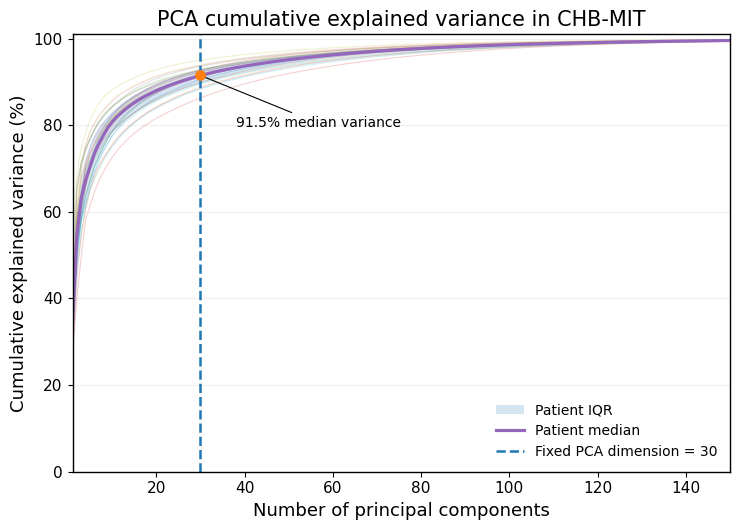

In [6]:
# ================================================================
# CHB-MIT manuscript/supplementary figure
# ================================================================

if RUN_CHBMIT and not chb_curves.empty:
    max_common_component = int(
        chb_curves.groupby("patient")["component"].max().min()
    )

    max_plot_component = min(max_common_component, 150)
    components = np.arange(1, max_plot_component + 1)

    matrix = []

    for patient, g in chb_curves.groupby("patient"):
        vals = (
            g.sort_values("component")
            .set_index("component")["cumulative_explained_variance"]
            .reindex(components)
            .to_numpy(dtype=float)
        )
        if np.isfinite(vals).all():
            matrix.append(vals)

    matrix = np.asarray(matrix)

    median_curve = np.nanmedian(matrix, axis=0)
    q25_curve = np.nanpercentile(matrix, 25, axis=0)
    q75_curve = np.nanpercentile(matrix, 75, axis=0)

    fig, ax = plt.subplots(figsize=(7.5, 5.4))

    for row in matrix:
        ax.plot(components, 100 * row, linewidth=0.8, alpha=0.22)

    ax.fill_between(
        components,
        100 * q25_curve,
        100 * q75_curve,
        alpha=0.18,
        label="Patient IQR",
    )

    ax.plot(
        components,
        100 * median_curve,
        linewidth=2.3,
        label="Patient median",
    )

    ax.axvline(
        TARGET_PCA,
        linestyle="--",
        linewidth=1.8,
        label=f"Fixed PCA dimension = {TARGET_PCA}",
    )

    if TARGET_PCA <= max_plot_component:
        med30 = 100 * median_curve[TARGET_PCA - 1]
        ax.scatter([TARGET_PCA], [med30], s=45, zorder=5)
        ax.annotate(
            f"{med30:.1f}% median variance",
            xy=(TARGET_PCA, med30),
            xytext=(TARGET_PCA + 8, max(5, med30 - 12)),
            fontsize=10,
            arrowprops=dict(arrowstyle="-", linewidth=0.8),
        )

    ax.set_xlabel("Number of principal components", fontsize=13)
    ax.set_ylabel("Cumulative explained variance (%)", fontsize=13)
    ax.tick_params(axis="both", labelsize=11)
    ax.set_xlim(1, max_plot_component)
    ax.set_ylim(0, 101)
    ax.grid(axis="y", alpha=0.18)
    ax.legend(frameon=False, fontsize=10, loc="lower right")

    ax.set_title("PCA cumulative explained variance in CHB-MIT",fontsize=15)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.0)

    fig.tight_layout()

    fig.savefig(
        FIG_DIR / "chbmit_pca_cumulative_explained_variance.png",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        FIG_DIR / "chbmit_pca_cumulative_explained_variance.pdf",
        bbox_inches="tight",
    )

    plt.show()


## Optional TUSZ PCA analysis

Enable `RUN_TUSZ = True` in the configuration cell. This section reuses the TUSZ v4 parser, common-16 montage, feature extraction, and patient-specific interictal split. It is useful if the manuscript states that the same fixed 30-PC representation was used for both datasets.


In [7]:
# ================================================================
# TUSZ: reuse the latest v4 parser + feature extraction
# ================================================================

tusz_summary_rows = []
tusz_curve_rows = []
tusz_errors = []

if RUN_TUSZ:
    tusz = import_script(TUSZ_V4_SCRIPT, "tusz_v4_pca_source")

    tusz_args = SimpleNamespace(
        data_root=str(TUSZ_DATA_ROOT),
        montage="",
        l_freq=0.5,
        h_freq=40.0,
        segment_seconds=30.0,
        chunk_seconds=5.0,
        stride_seconds=1.0,
        min_sequence_chunks=20,
        interictal_pre_buffer_seconds=120.0,
        interictal_post_buffer_seconds=120.0,
        interictal_scan_stride_seconds=60.0,
        max_interictal_scans_per_patient=200,
        train_fraction=0.50,
        val_fraction=0.25,
        data_seed=DATA_SEED,
        verbose=False,
    )

    print("Indexing TUSZ once...")
    edf_index, all_seizures = tusz.index_tusz(
        TUSZ_DATA_ROOT, tusz_args.montage
    )
    print("EDFs indexed:", len(edf_index))
    print("Seizures indexed:", len(all_seizures))

    for patient in TUSZ_PATIENTS:
        try:
            train_scans, val_scans, test_scans, ictal_scans, patient_seizures = (
                tusz.prepare_patient_scans(
                    patient, tusz_args, edf_index, all_seizures
                )
            )

            train_raw = tusz.scans_to_features(train_scans, tusz_args)

            if len(train_raw) == 0:
                raise RuntimeError("No usable training interictal sequences")

            train_mat = np.vstack([seq.features for seq in train_raw])

            summary_row, curve = summarize_patient_pca(
                patient=patient,
                train_mat=train_mat,
                dataset="TUSZ",
            )

            summary_row.update({
                "indexed_seizures": len(patient_seizures),
                "train_scans_requested": len(train_scans),
                "train_scans_usable": len(train_raw),
                "val_scans": len(val_scans),
                "test_scans": len(test_scans),
                "ictal_scans": len(ictal_scans),
            })

            tusz_summary_rows.append(summary_row)
            tusz_curve_rows.append(curve)

            print(
                f"{patient}: train rows={train_mat.shape[0]:5d}, "
                f"features={train_mat.shape[1]}, "
                f"variance@30={summary_row['variance_at_30_percent']:.1f}%, "
                f"PCs@90%={summary_row['pcs_for_90pct']}, "
                f"PCs@95%={summary_row['pcs_for_95pct']}"
            )

        except Exception as exc:
            tusz_errors.append({
                "dataset": "TUSZ",
                "patient": patient,
                "error": str(exc),
            })
            print(f"[TUSZ ERROR] {patient}: {exc}")

    tusz_summary = pd.DataFrame(tusz_summary_rows)
    tusz_curves = (
        pd.concat(tusz_curve_rows, ignore_index=True)
        if tusz_curve_rows else pd.DataFrame()
    )
    tusz_error_df = pd.DataFrame(tusz_errors)

    tusz_summary.to_csv(
        TABLE_DIR / "tusz_pca_patient_summary.csv", index=False
    )
    tusz_curves.to_csv(
        TABLE_DIR / "tusz_pca_cumulative_variance_curves.csv", index=False
    )
    tusz_error_df.to_csv(
        TABLE_DIR / "tusz_pca_errors.csv", index=False
    )

    print("\nCompleted TUSZ patients:", len(tusz_summary))
    print("TUSZ errors/skips:", len(tusz_error_df))
else:
    tusz_summary = pd.DataFrame()
    tusz_curves = pd.DataFrame()
    tusz_error_df = pd.DataFrame()


Indexing TUSZ once...
EDFs indexed: 8140
Seizures indexed: 2663
aaaaapks: train rows= 2600, features=240, variance@30=91.9%, PCs@90%=25, PCs@95%=45
aaaaaqtx: train rows= 2600, features=240, variance@30=94.8%, PCs@90%=17, PCs@95%=32
aaaaahie: train rows= 2600, features=240, variance@30=93.9%, PCs@90%=18, PCs@95%=36
aaaaajqo: train rows= 2600, features=240, variance@30=90.4%, PCs@90%=30, PCs@95%=50
aaaaajru: train rows= 2600, features=240, variance@30=90.3%, PCs@90%=30, PCs@95%=51
aaaaaovk: train rows=  312, features=240, variance@30=97.1%, PCs@90%=10, PCs@95%=20
aaaaardk: train rows= 2600, features=240, variance@30=95.6%, PCs@90%=13, PCs@95%=27
aaaaabhz: train rows=  676, features=240, variance@30=94.8%, PCs@90%=17, PCs@95%=31
aaaaampk: train rows= 2600, features=240, variance@30=93.8%, PCs@90%=20, PCs@95%=36
aaaaaprj: train rows= 2600, features=240, variance@30=96.0%, PCs@90%=12, PCs@95%=25
aaaaafcf: train rows= 1040, features=240, variance@30=95.2%, PCs@90%=14, PCs@95%=29
aaaaaqkb: tr

,patient,training_feature_rows,raw_feature_dimension,variance_at_30_percent,pcs_for_80pct,pcs_for_90pct,pcs_for_95pct,pcs_for_99pct
61,aaaaaarq,2600,240,95.474303,6,14,28,72
37,aaaaaasf,260,240,87.908286,20,35,50,88
32,aaaaaasy,1092,240,95.779407,5,13,26,72
60,aaaaaayf,1404,240,92.879105,9,21,41,101
7,aaaaabhz,676,240,94.790488,8,17,31,77
...,...,...,...,...,...,...,...,...
42,aaaaaswc,1092,240,84.367180,23,45,70,120
53,aaaaatds,2600,240,96.275038,5,12,24,65
24,aaaaates,2600,240,94.548666,8,18,33,75
17,aaaaatez,1820,240,93.838346,7,19,36,76



TUSZ cohort summary
variance_at_30_percent    : median=93.17, IQR=(91.32, 94.79), range=(84.37, 97.13)
pcs_for_80pct             : median=10.00, IQR=(7.00, 12.00), range=(4.00, 23.00)
pcs_for_90pct             : median=21.00, IQR=(17.00, 27.00), range=(8.00, 45.00)
pcs_for_95pct             : median=38.00, IQR=(31.50, 46.00), range=(18.00, 70.00)
pcs_for_99pct             : median=84.00, IQR=(72.50, 99.50), range=(53.00, 120.00)


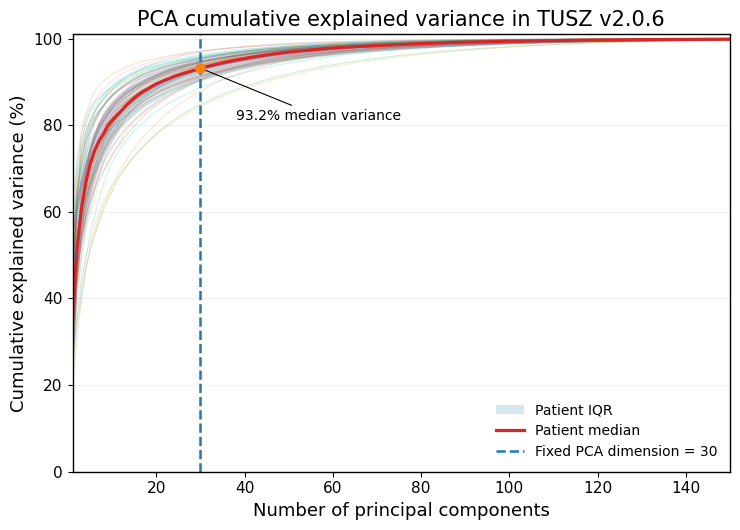

In [8]:
# ================================================================
# TUSZ summary + optional manuscript-quality figure
# ================================================================

if RUN_TUSZ and not tusz_summary.empty:
    cols = [
        "variance_at_30_percent",
        "pcs_for_80pct",
        "pcs_for_90pct",
        "pcs_for_95pct",
        "pcs_for_99pct",
    ]

    display(tusz_summary[
        ["patient", "training_feature_rows", "raw_feature_dimension"] + cols
    ].sort_values("patient"))

    print("\nTUSZ cohort summary")
    print("=" * 60)

    for col in cols:
        x = pd.to_numeric(tusz_summary[col], errors="coerce").dropna()
        print(
            f"{col:26s}: "
            f"median={x.median():.2f}, "
            f"IQR=({x.quantile(0.25):.2f}, {x.quantile(0.75):.2f}), "
            f"range=({x.min():.2f}, {x.max():.2f})"
        )

    max_common_component = int(
        tusz_curves.groupby("patient")["component"].max().min()
    )
    max_plot_component = min(max_common_component, 150)
    components = np.arange(1, max_plot_component + 1)

    matrix = []
    for patient, g in tusz_curves.groupby("patient"):
        vals = (
            g.sort_values("component")
            .set_index("component")["cumulative_explained_variance"]
            .reindex(components)
            .to_numpy(dtype=float)
        )
        if np.isfinite(vals).all():
            matrix.append(vals)

    matrix = np.asarray(matrix)

    median_curve = np.nanmedian(matrix, axis=0)
    q25_curve = np.nanpercentile(matrix, 25, axis=0)
    q75_curve = np.nanpercentile(matrix, 75, axis=0)

    fig, ax = plt.subplots(figsize=(7.5, 5.4))

    for row in matrix:
        ax.plot(components, 100 * row, linewidth=0.8, alpha=0.22)

    ax.fill_between(
        components,
        100 * q25_curve,
        100 * q75_curve,
        alpha=0.18,
        label="Patient IQR",
    )

    ax.plot(
        components,
        100 * median_curve,
        linewidth=2.3,
        label="Patient median",
    )

    ax.axvline(
        TARGET_PCA,
        linestyle="--",
        linewidth=1.8,
        label=f"Fixed PCA dimension = {TARGET_PCA}",
    )

    if TARGET_PCA <= max_plot_component:
        med30 = 100 * median_curve[TARGET_PCA - 1]
        ax.scatter([TARGET_PCA], [med30], s=45, zorder=5)
        ax.annotate(
            f"{med30:.1f}% median variance",
            xy=(TARGET_PCA, med30),
            xytext=(TARGET_PCA + 8, max(5, med30 - 12)),
            fontsize=10,
            arrowprops=dict(arrowstyle="-", linewidth=0.8),
        )

    ax.set_xlabel("Number of principal components", fontsize=13)
    ax.set_ylabel("Cumulative explained variance (%)", fontsize=13)
    ax.tick_params(axis="both", labelsize=11)
    ax.set_xlim(1, max_plot_component)
    ax.set_ylim(0, 101)
    ax.grid(axis="y", alpha=0.18)
    ax.legend(frameon=False, fontsize=10, loc="lower right")

    ax.set_title("PCA cumulative explained variance in TUSZ v2.0.6", fontsize=15)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.0)

    fig.tight_layout()

    fig.savefig(
        FIG_DIR / "tusz_pca_cumulative_explained_variance.png",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        FIG_DIR / "tusz_pca_cumulative_explained_variance.pdf",
        bbox_inches="tight",
    )

    plt.show()
